# 09. Semantic Similarity & Duplicate Detection Evaluation

Forensic evaluation of dense Sentence Transformer embeddings for duplicate achievement detection on the split-isolated 300-pair benchmark, analyzing threshold calibration, ROC-AUC, PR-AUC, and distinguishing semantic proximity from logical identity.

**Dataset Release:** `achievement_dataset_v1.0.1` | **Author:** Member 1 (NLP & Semantic Intelligence Engineer)

## 1. Benchmark Dataset Loading & Split Isolation
We load `data/annotations/achievement_duplicate_pairs.csv` (300 pairs) across train (210), validation (46), and test (44) partitions.

In [1]:
import os
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

from nlp.embedding import (
    load_embedding_model,
    generate_embeddings,
    compute_pairwise_cosine_similarity
)

pairs_path = REPO_ROOT / "data" / "annotations" / "achievement_duplicate_pairs.csv"
pairs_df = pd.read_csv(pairs_path)

print(f"Loaded Duplicate Pairs Benchmark: {len(pairs_df)} total pairs.")
print("\nPartition Breakdown:")
print(pairs_df.groupby(["split", "duplicate_label"]).size().unstack().fillna(0).astype(int))

Loaded Duplicate Pairs Benchmark: 300 total pairs.
Partition Breakdown:
duplicate_label    0    1
split                    
test              22   22
train            105  105
validation        23   23


## 2. Generate Pair Embeddings & Compute Cosine Similarity
We encode `text_1` and `text_2` using `all-MiniLM-L6-v2` and compute pairwise cosine similarity.

In [2]:
model = load_embedding_model("all-MiniLM-L6-v2", device="cpu")

t1_embs = generate_embeddings(pairs_df["text_1"].tolist(), model, normalize_embeddings=True)
t2_embs = generate_embeddings(pairs_df["text_2"].tolist(), model, normalize_embeddings=True)

pairs_df["cosine_similarity"] = compute_pairwise_cosine_similarity(t1_embs, t2_embs)

print("Pairwise Cosine Similarity Computed Successfully.")
print(pairs_df[["duplicate_type", "duplicate_label", "cosine_similarity"]].head(5).to_string())

Pairwise Cosine Similarity Computed Successfully.
              duplicate_type  duplicate_label  cosine_similarity
0    PARAPHRASE_RESTRUCTURED                1           0.831071
1  OFFICIAL_CITATION_VARIANT                1           0.816513
2      RESUME_BULLET_VARIANT                1           0.739604
3      RESUME_BULLET_VARIANT                1           0.727655
4  OFFICIAL_CITATION_VARIANT                1           0.830178


## 3. Cosine Similarity Distribution Analysis
We visualize the similarity distributions of positive duplicate pairs vs. negative non-duplicate pairs across different duplicate types.

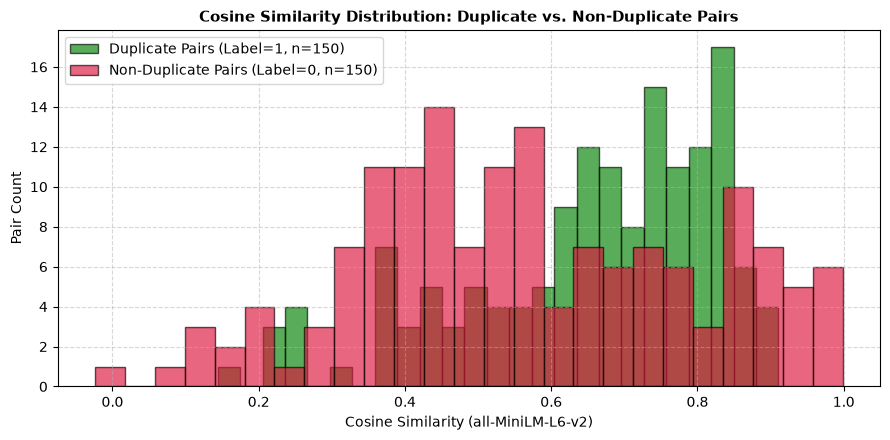

In [3]:
pos_sims = pairs_df[pairs_df["duplicate_label"] == 1]["cosine_similarity"]
neg_sims = pairs_df[pairs_df["duplicate_label"] == 0]["cosine_similarity"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(pos_sims, bins=25, alpha=0.65, color="green", label=f"Duplicate Pairs (Label=1, n={len(pos_sims)})", edgecolor="black")
ax.hist(neg_sims, bins=25, alpha=0.65, color="crimson", label=f"Non-Duplicate Pairs (Label=0, n={len(neg_sims)})", edgecolor="black")

ax.set_title("Cosine Similarity Distribution: Duplicate vs. Non-Duplicate Pairs", fontsize=11, fontweight="bold")
ax.set_xlabel("Cosine Similarity (all-MiniLM-L6-v2)")
ax.set_ylabel("Pair Count")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

## 4. Validation Split Threshold Search Grid (Zero Data Leakage)
Using strictly the 46 validation pairs, we sweep candidate thresholds $\tau \in [0.40, 0.90]$ to find $\tau^*$ maximizing F1.

In [4]:
val_df = pairs_df[pairs_df["split"] == "validation"].copy()
y_val = val_df["duplicate_label"].to_numpy()
sims_val = val_df["cosine_similarity"].to_numpy()

sweep_rows = []
best_tau = 0.50
best_f1 = -1.0

for tau in np.arange(0.40, 0.91, 0.02):
    preds = (sims_val >= tau).astype(int)
    acc = accuracy_score(y_val, preds)
    p = precision_score(y_val, preds, zero_division=0)
    r = recall_score(y_val, preds, zero_division=0)
    f1 = f1_score(y_val, preds, zero_division=0)
    
    sweep_rows.append({
        "Threshold": round(tau, 2),
        "Accuracy": round(acc, 4),
        "Precision": round(p, 4),
        "Recall": round(r, 4),
        "F1-Score": round(f1, 4)
    })
    if f1 > best_f1:
        best_f1 = f1
        best_tau = tau

sweep_df = pd.DataFrame(sweep_rows)
val_roc = roc_auc_score(y_val, sims_val)
val_pr = average_precision_score(y_val, sims_val)

print(f"=== VALIDATION THRESHOLD SWEEP SUMMARY ===")
print(f"Optimal Threshold (tau*): {best_tau:.2f}")
print(f"Validation F1-Score:      {best_f1:.4f}")
print(f"Validation ROC-AUC:       {val_roc:.4f}")
print(f"Validation PR-AUC:        {val_pr:.4f}")
print("\nTop 5 Threshold Candidates on Validation Set:")
print(sweep_df.sort_values(by="F1-Score", ascending=False).head(5).to_string(index=False))

=== VALIDATION THRESHOLD SWEEP SUMMARY ===
Optimal Threshold (tau*): 0.58
Validation F1-Score:      0.7347
Validation ROC-AUC:       0.6541
Validation PR-AUC:        0.5770
Top 5 Threshold Candidates on Validation Set:
 Threshold  Accuracy  Precision  Recall  F1-Score
      0.58    0.7174     0.6923  0.7826    0.7347
      0.54    0.6957     0.6552  0.8261    0.7308
      0.56    0.6957     0.6667  0.7826    0.7200
      0.60    0.6957     0.6800  0.7391    0.7083
      0.48    0.6522     0.6129  0.8261    0.7037


## 5. Unbiased Held-Out Test Split Evaluation
We evaluate the frozen threshold $\tau^*$ strictly on the 44 held-out test pairs.

=== UNBIASED HELD-OUT TEST EVALUATION (tau* = 0.58) ===
Test Accuracy:    0.7045
Test Precision:   0.6667
Test Recall:      0.8182
Test F1-Score:    0.7347
Test ROC-AUC:     0.5517
Test PR-AUC:      0.5013


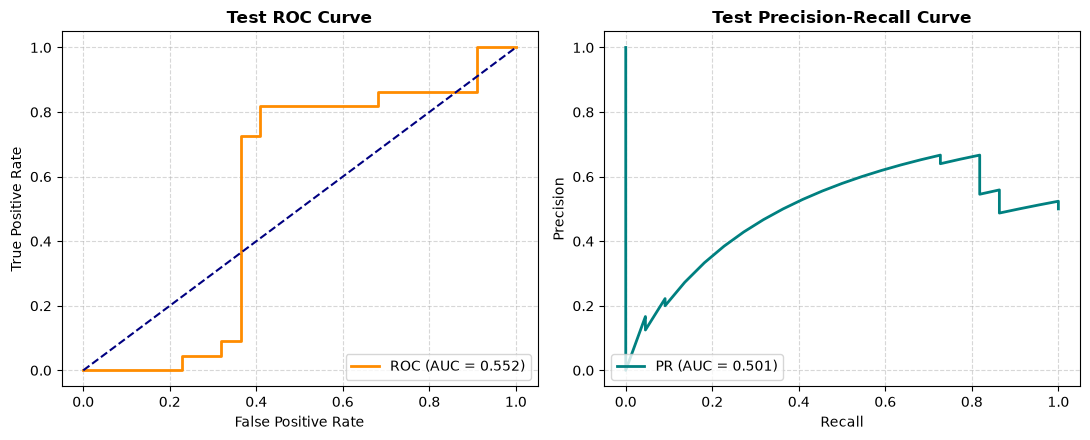

In [5]:
test_df = pairs_df[pairs_df["split"] == "test"].copy()
y_test = test_df["duplicate_label"].to_numpy()
sims_test = test_df["cosine_similarity"].to_numpy()

test_preds = (sims_test >= best_tau).astype(int)
test_acc = accuracy_score(y_test, test_preds)
test_p = precision_score(y_test, test_preds, zero_division=0)
test_r = recall_score(y_test, test_preds, zero_division=0)
test_f1 = f1_score(y_test, test_preds, zero_division=0)
test_roc = roc_auc_score(y_test, sims_test)
test_pr = average_precision_score(y_test, sims_test)

print(f"=== UNBIASED HELD-OUT TEST EVALUATION (tau* = {best_tau:.2f}) ===")
print(f"Test Accuracy:    {test_acc:.4f}")
print(f"Test Precision:   {test_p:.4f}")
print(f"Test Recall:      {test_r:.4f}")
print(f"Test F1-Score:    {test_f1:.4f}")
print(f"Test ROC-AUC:     {test_roc:.4f}")
print(f"Test PR-AUC:      {test_pr:.4f}")

# Plot ROC and PR curves
fpr, tpr, _ = roc_curve(y_test, sims_test)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, sims_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC (AUC = {test_roc:.3f})")
ax1.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--")
ax1.set_title("Test ROC Curve", fontweight="bold")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.legend(loc="lower right")
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(rec_curve, prec_curve, color="teal", lw=2, label=f"PR (AUC = {test_pr:.3f})")
ax2.set_title("Test Precision-Recall Curve", fontweight="bold")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend(loc="lower left")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

## 6. Error Analysis: False Positives & False Negatives
We investigate why dense similarity alone confuses distinct achievements that share competitive domains.

In [6]:
test_df["prediction"] = test_preds

fps = test_df[(test_df["prediction"] == 1) & (test_df["duplicate_label"] == 0)]
fns = test_df[(test_df["prediction"] == 0) & (test_df["duplicate_label"] == 1)]

print(f"Total Test False Positives: {len(fps)}")
print(f"Total Test False Negatives: {len(fns)}")

if len(fps) > 0:
    print("\nRepresentative False Positive (Distinct achievements with high semantic overlap):")
    sample_fp = fps.iloc[0]
    print(f"Pair ID:    {sample_fp['pair_id']}")
    print(f"Type:       {sample_fp['duplicate_type']}")
    print(f"Similarity: {sample_fp['cosine_similarity']:.4f}")
    print(f"Text 1:     {sample_fp['text_1']}")
    print(f"Text 2:     {sample_fp['text_2']}")

Total Test False Positives: 9
Total Test False Negatives: 4
Representative False Positive (Distinct achievements with high semantic overlap):
Pair ID:    PAIR_00279
Type:       SAME_EVENT_DIFFERENT_ACHIEVEMENT
Similarity: 0.9050
Text 1:     Received the University Gold Medal for securing Rank 1 across all 8 semesters of the Bachelor of Technology degree in Computer Science and Engineering at RV College of Engineering, Bengaluru.
Text 2:     Received the University Gold Medal for securing Rank 1 across all 8 semesters of the Bachelor of Technology degree in Information Technology at Indian Institute of Engineering Science and Technology, Shibpur.


## 7. Crucial Architectural Distinction: Similar vs Duplicate
- **Similar Achievements:** Two records in the same competition (e.g. Smart India Hackathon) or domain with high cosine similarity (~0.60–0.70), but describing completely distinct projects. Cosine threshold alone produces false merges.
- **Genuine Duplicate Records:** Paraphrases or resume variants describing the identical student achievement.
- **Production Rule:** Cosine similarity should serve as a candidate retrieval stage, followed by entity verification (project names, dates, ranks).